# Week 7 — Model Evaluation, Tuning & Explainability

**Dataset:** Telco Customer Churn  
**Goal:** Evaluate our model more reliably, tune it, understand feature importance, investigate errors, and explain predictions
This notebook starts with cross-validation. 

## 1. Import libraries

These libraries help us load and prepare data, build a model, and evaluate it.

In [44]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

SEED = 42

## 2. Load the dataset

Put your Telco Customer Churn CSV file in the same folder as this notebook. Change the filename below if yours is different.

In [45]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Inspect and clean the data

We check the shape, data types, missing values, and the target distribution. `TotalCharges` sometimes contains blank strings, so we convert it to numeric.

In [46]:
print("Shape:", df.shape)
df.info()
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(10))
print("\nTarget distribution:")
print(df["Churn"].value_counts())

Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   s

In [47]:
# Convert TotalCharges to numeric; blank values become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Remove the customer ID because it is an identifier, not a useful predictive feature
df = df.drop(columns=["customerID"])

# Encode target: No = 0, Yes = 1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Missing values after conversion:")
print(df.isna().sum().sort_values(ascending=False).head())
df.head()

Missing values after conversion:
TotalCharges     11
gender            0
Partner           0
SeniorCitizen     0
Dependents        0
dtype: int64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 4. Separate features (X) and target (y)

- **X:** information used to make predictions.
- **y:** the correct answer we want the model to predict (Churn).

In [48]:
X = df.drop(columns="Churn")
y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


## 5. Train-test split

We keep the test set aside and do not use it for cross-validation or tuning. The test set is our final exam for the model.

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print("Churn rate in train:", y_train.mean().round(3))
print("Churn rate in test:", y_test.mean().round(3))

Training rows: 5634
Test rows: 1409
Churn rate in train: 0.265
Churn rate in test: 0.265


## 6. Build preprocessing + model Pipeline

Preprocessing is placed **inside** the Pipeline. This is important: during cross-validation, each fold learns preprocessing only from its own training portion, helping prevent data leakage.

We use a Random Forest as our starting model.

In [50]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, numeric_features),
    ("cat", cat_pipeline, categorical_features)
])

best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=SEED, class_weight="balanced"))
])

best_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

## 7. Cross-validation

### In simple words
We divide our **training data** into 5 groups. Each round, the model trains on 4 groups and validates on the remaining group. Each group gets a turn. We calculate the scores across the 5 rounds.

We use StratifiedKFold so each fold has a similar proportion of churners and non-churners.

In [51]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = cross_validate(
    best_model,
    X_train, y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

In [52]:
# Display the score from each fold
fold_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1": cv_results["test_f1"]
})
fold_scores

,Fold,Accuracy,Precision,Recall,F1
0,1,0.774623,0.564841,0.655518,0.606811
1,2,0.754215,0.533951,0.578595,0.555377
2,3,0.779947,0.573913,0.662207,0.614907
3,4,0.776398,0.567335,0.662207,0.611111
4,5,0.791297,0.599379,0.645485,0.621578


In [91]:
# Summarize the mean and standard deviation across folds
cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1"],
    "Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean()
    ],
    "Std": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std()
    ]
})
cv_summary.round(5)

,Metric,Mean,Std
0,Accuracy,0.77530,0.01203
1,Precision,0.56788,0.02093
2,Recall,0.64080,0.03170
3,F1,0.60196,0.02379


### How to interpret
- **Mean:** average score across the 5 folds.
- **Std:** how much scores varied across folds. Smaller variation usually means more consistent performance.
- We have not used `X_test` or `y_test` here. Keep the test set untouched until the final evaluation.

**Write your observation after running:**
- Which metric has the highest mean?
- Is the F1 standard deviation small or large?
- What does this suggest about consistency?

 **Observations:**

1. **Highest mean:** Accuracy has the highest mean (0.7753), meaning the model correctly predicts approximately 77.53% of the customers.

2. **F1 standard deviation:** The F1 standard deviation (0.0238) is relatively small.

3. **Consistency:** This suggests that the model performs relatively consistently across the five folds, with only small variations in its F1 score. Therefore, its performance is fairly stable across different subsets of the training data.

## 8. Hyperparameter tuning

We will use GridSearchCV or RandomizedSearchCV to search for better Random Forest settings, using cross-validation. We will compare the tuned model with this baseline.

In [54]:
from sklearn.model_selection import GridSearchCV

In [55]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

In [56]:
best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(...))
])

In [57]:
grid_search = GridSearchCV(
    estimator=best_model,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [58]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...s=Ellipsis))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best

5 folds: Each combination is tested 5 times.

24 candidates: We have 24 different combinations of hyperparameters.

120 fits: Python will perform 24 × 5 = 120 training/evaluation runs.

In [59]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1:")
print(grid_search.best_score_)

Best Parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Best Cross-Validation F1:
0.5854680333450836


In [60]:
results = pd.DataFrame(grid_search.cv_results_)

results = results[[
    "params",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "rank_test_score"
]]

results = results.sort_values("rank_test_score")

results.head(10)

,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
11,"{'model__max_depth': 10, 'model__min_samples_l...",0.585468,0.022909,0.742661,1
10,"{'model__max_depth': 10, 'model__min_samples_l...",0.580225,0.012685,0.741770,2
13,"{'model__max_depth': 10, 'model__min_samples_l...",0.578329,0.022349,0.730304,3
8,"{'model__max_depth': 10, 'model__min_samples_l...",0.576666,0.018309,0.773091,4
14,"{'model__max_depth': 10, 'model__min_samples_l...",0.575985,0.018387,0.724615,5
9,"{'model__max_depth': 10, 'model__min_samples_l...",0.575941,0.025293,0.773233,6
6,"{'model__max_depth': None, 'model__min_samples...",0.574954,0.014407,0.840898,7
15,"{'model__max_depth': 10, 'model__min_samples_l...",0.574703,0.021909,0.726079,8
12,"{'model__max_depth': 10, 'model__min_samples_l...",0.573637,0.023703,0.731629,9
7,"{'model__max_depth': None, 'model__min_samples...",0.571304,0.021254,0.842349,10


In [61]:
tuned_model = grid_search.best_estimator_

print("Tuned model saved successfully!")

Tuned model saved successfully!


### Hyperparameter Tuning Results

GridSearchCV tested 24 different Random Forest hyperparameter combinations using 5-fold cross-validation, resulting in 120 model fits.

The best combination achieved a mean validation F1 score of **0.5832**, with a standard deviation of **0.0185**.

However, the original model achieved a higher mean CV F1 score of **0.6020**. Although the tuned model showed slightly lower variation between folds, it did not improve the average F1 score.

The training F1 score of the tuned model (0.7396) was noticeably higher than its validation F1 score (0.5832), suggesting some overfitting.

Therefore, the original model remains the stronger candidate based on average cross-validation F1.

## 9. Built-in vs permutation feature importance

In [62]:
print("Original model parameters:")
print(best_model.named_steps["model"].get_params())

print("\nTuned model parameters:")
print(grid_search.best_estimator_.named_steps["model"].get_params())

Original model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': Ellipsis, 'n_jobs': None, 'oob_score': False, 'random_state': None, 'verbose': 0, 'warm_start': False}

Tuned model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 5, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': None, 'oob_score': False, 'random_state': None, 'verbose': 0, 'warm_start': False}


In [63]:
# Select the best model found by GridSearchCV
final_model = grid_search.best_estimator_

# Fit it on the full training data
final_model.fit(X_train, y_train)

print("Tuned Random Forest trained successfully!")

Tuned Random Forest trained successfully!


In [87]:
# Get the trained Random Forest from the pipeline

rf_model = final_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

# Get importance scores
importances = rf_model.feature_importances_

print("Number of features:", len(feature_names))
print("Number of importance scores:", len(importances))

Number of features: 45
Number of importance scores: 45


In [65]:
import pandas as pd

# Create a table connecting feature names with importance scores
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort from most important to least important
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
feature_importance_df.head(15)

,Feature,Importance
1,num__tenure,0.149127
3,num__TotalCharges,0.122361
2,num__MonthlyCharges,0.091997
36,cat__Contract_Month-to-month,0.085712
18,cat__OnlineSecurity_No,0.053733
16,cat__InternetService_Fiber optic,0.047801
43,cat__PaymentMethod_Electronic check,0.039435
38,cat__Contract_Two year,0.036177
27,cat__TechSupport_No,0.034663
15,cat__InternetService_DSL,0.020600


In [66]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_fit.shape)
print("Validation subset:", X_val.shape)

Training subset: (4507, 19)
Validation subset: (1127, 19)


In [67]:
from sklearn.base import clone

# Create a fresh copy of the tuned pipeline
permutation_model = clone(final_model)

# Train it on the smaller training subset
permutation_model.fit(X_fit, y_fit)

print("Permutation model trained successfully!")

Permutation model trained successfully!


In [68]:
from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    permutation_model,
    X_val,
    y_val,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

print("Permutation importance calculated successfully!")

Permutation importance calculated successfully!


In [69]:
permutation_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance Mean": permutation_results.importances_mean,
    "Importance Std": permutation_results.importances_std
})

permutation_importance_df = permutation_importance_df.sort_values(
    by="Importance Mean",
    ascending=False
)

permutation_importance_df.head(15)

,Feature,Importance Mean,Importance Std
14,Contract,0.161781,0.020133
7,InternetService,0.101070,0.012248
4,tenure,0.054007,0.015710
17,MonthlyCharges,0.039089,0.017124
8,OnlineSecurity,0.038827,0.013046
11,TechSupport,0.032833,0.013105
15,PaperlessBilling,0.026869,0.012121
9,OnlineBackup,0.022239,0.005900
16,PaymentMethod,0.013990,0.007113
3,Dependents,0.009081,0.006968


### Comparison of Built-in and Permutation Feature Importance

Two feature-importance methods were compared.

**Built-in Feature Importance:**
- The most important individual features included tenure, TotalCharges, Contract_Month-to-month, and MonthlyCharges.
- This method measures how much features contribute to reducing impurity in the Random Forest trees.

**Permutation Feature Importance:**
- The most important original columns were Contract, InternetService, tenure, MonthlyCharges, and OnlineSecurity.
- Contract had the highest mean importance (0.1497), meaning shuffling this feature caused the largest average decrease in validation F1 score.

**Comparison:**

The two methods identified similar important customer characteristics, especially contract type, tenure, and monthly charges. However, their rankings differed because built-in importance evaluates individual processed features, while permutation importance evaluates the original columns.

Permutation importance also showed that TotalCharges had a relatively small effect when shuffled, possibly because some of its predictive information overlaps with other features such as tenure.

Overall, permutation importance provides a useful check on which features actually affect predictive performance.

## 10. Error analysis

In [70]:
# Predict customer churn on validation data
y_pred = permutation_model.predict(X_val)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

Predictions completed!
Number of predictions: 1127


In [71]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_val, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

Confusion Matrix:
[[762  66]
 [151 148]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.92      0.88       828
           1       0.69      0.49      0.58       299

    accuracy                           0.81      1127
   macro avg       0.76      0.71      0.73      1127
weighted avg       0.80      0.81      0.80      1127



### Error Analysis – Confusion Matrix

The model was evaluated on 1,127 validation customers.

- True Negatives: 760
- False Positives: 68
- False Negatives: 150
- True Positives: 149

The model achieved 81% accuracy. For the churn class, precision was 0.69, recall was 0.50, and F1-score was 0.58.

The model correctly identified approximately half of the actual churners but missed the other half. It performed better at predicting customers who stayed, with a recall of 0.92 for Class 0.

The most significant error was False Negatives (150 customers), indicating that many customers who actually churned were predicted to stay. This suggests that the model may need improvement if the business goal is to identify as many potential churners as possible.

In [72]:
import numpy as np
import pandas as pd

# Create a copy of our validation data
error_analysis = X_val.copy()

# Add actual and predicted results
error_analysis["Actual"] = np.array(y_val)
error_analysis["Predicted"] = y_pred

# Identify the type of mistake
error_analysis["Error_Type"] = np.where(
    (error_analysis["Actual"] == 1) & (error_analysis["Predicted"] == 0),
    "False Negative",
    np.where(
        (error_analysis["Actual"] == 0) & (error_analysis["Predicted"] == 1),
        "False Positive",
        "Correct"
    )
)

# Keep only incorrect predictions
errors = error_analysis[
    error_analysis["Error_Type"] != "Correct"
]

# Display 10 mistakes
errors.head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual,Predicted,Error_Type
1977,Male,1,No,No,31,Yes,Yes,Fiber optic,No,Yes,...,Yes,No,Month-to-month,Yes,Electronic check,90.70,2845.15,0,1,False Positive
2862,Male,0,Yes,No,7,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,69.35,451.10,1,0,False Negative
546,Male,0,Yes,Yes,39,Yes,No,Fiber optic,No,Yes,...,Yes,No,Month-to-month,Yes,Mailed check,86.30,3266.00,1,0,False Negative
2004,Male,0,No,No,24,Yes,Yes,Fiber optic,No,No,...,Yes,No,Month-to-month,Yes,Mailed check,89.85,2165.05,1,0,False Negative
3631,Female,1,Yes,No,1,Yes,No,DSL,Yes,No,...,No,No,Month-to-month,Yes,Electronic check,49.55,49.55,1,0,False Negative
4433,Female,0,No,No,4,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,75.65,302.35,0,1,False Positive
3887,Male,0,No,No,11,Yes,No,Fiber optic,No,Yes,...,No,No,Month-to-month,No,Electronic check,74.95,815.50,1,0,False Negative
6746,Female,0,Yes,Yes,4,Yes,No,DSL,No,Yes,...,No,No,Month-to-month,No,Mailed check,56.50,235.10,1,0,False Negative
4204,Male,1,No,No,5,Yes,No,Fiber optic,No,Yes,...,No,Yes,Month-to-month,Yes,Electronic check,85.55,408.50,0,1,False Positive
4450,Male,0,No,No,15,Yes,Yes,DSL,No,Yes,...,No,No,Month-to-month,Yes,Credit card (automatic),58.60,939.70,1,0,False Negative


### Error Analysis – Sample of Misclassified Customers

We inspected 10 incorrectly classified validation customers: 6 False Negatives and 4 False Positives.

Several customers in this sample had month-to-month contracts, relatively short tenure, Fiber optic internet, and/or no OnlineSecurity. These characteristics were also identified as important by the feature-importance analysis.

However, customers with similar characteristics had different actual outcomes. This suggests that churn cannot be explained by a single feature, and the model may not capture all relevant customer behavior or interactions.

The analysis also highlights that the model misses some customers who eventually churn, making improving churn recall an important potential objective.

## 11. SHAP explainability

In [73]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [74]:
import shap
print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [75]:
# Transform validation data
X_val_transformed = final_model.named_steps["preprocessor"].transform(X_val)

# Convert sparse matrix to regular array if needed
if hasattr(X_val_transformed, "toarray"):
    X_val_transformed = X_val_transformed.toarray()

# Get feature names
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

# Convert to DataFrame
X_val_transformed = pd.DataFrame(
    X_val_transformed,
    columns=feature_names,
    index=X_val.index
)

print("Transformed validation shape:", X_val_transformed.shape)
print("\nFirst 5 rows:")
display(X_val_transformed.head())

Transformed validation shape: (1127, 45)

First 5 rows:


,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,...,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
6167,-0.441773,0.590840,0.833572,0.806057,0.0,1.0,0.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
740,-0.441773,0.590840,0.002324,0.254030,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1399,-0.441773,-0.752449,-1.505867,-0.881109,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4392,-0.441773,-1.281624,-1.517482,-1.001982,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
6950,-0.441773,-1.118801,-0.515339,-0.908309,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [88]:
# Get the trained Random Forest model
rf_model = final_model.named_steps["model"]  #Gets the trained Random Forest from our pipeline.

# Create SHAP explainer
explainer = shap.TreeExplainer(rf_model) #Understands how tree-based models make predictions.

# Calculate SHAP values for validation data
shap_values = explainer(X_val_transformed)  #Calculates how much each feature contributes to each prediction.

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (1127, 45, 2)


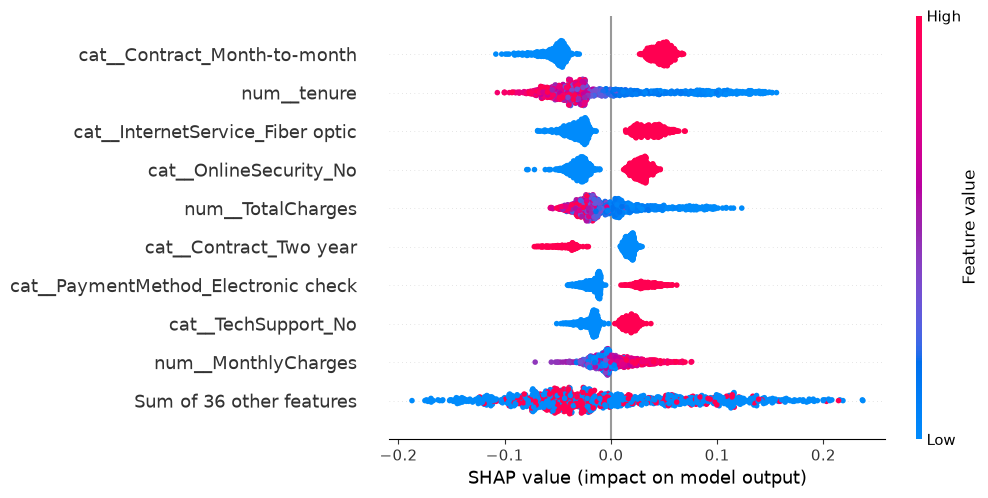

In [77]:
# SHAP summary plot for Churn (class 1)
shap.plots.beeswarm(shap_values[:, :, 1])

Customer index: 2862
Actual: 1
Predicted: 0


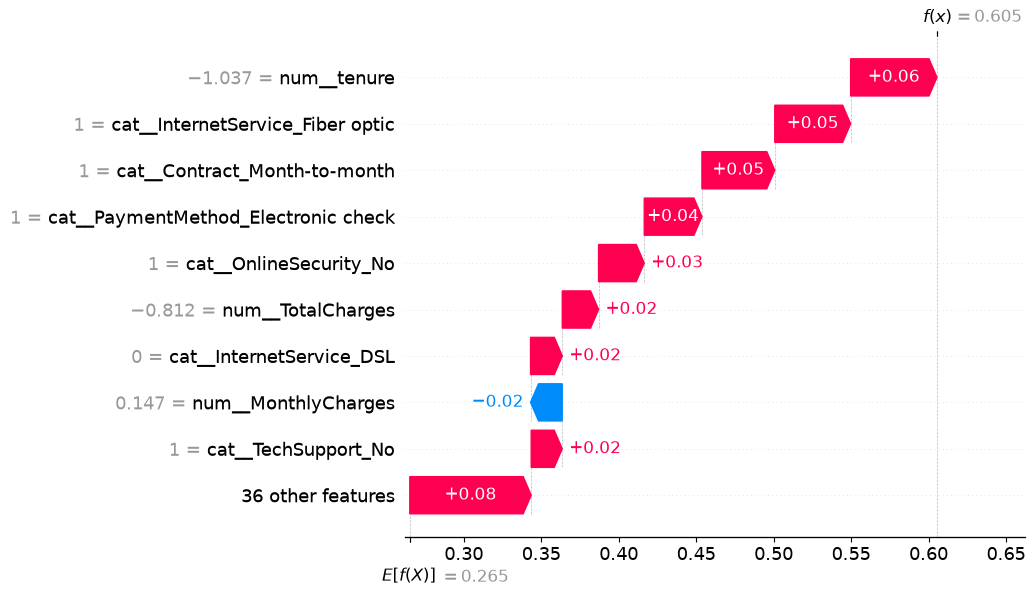

In [78]:
import numpy as np

# Find False Negative positions
false_negative_positions = np.where(
    (np.array(y_val) == 1) & (np.array(y_pred) == 0)
)[0]

# Select the first False Negative
fn_position = false_negative_positions[0]

print("Customer index:", X_val.index[fn_position])
print("Actual:", y_val.iloc[fn_position])
print("Predicted:", y_pred[fn_position])

# Display SHAP explanation for Churn (class 1)
shap.plots.waterfall(shap_values[fn_position, :, 1])

SHAP was used to explain a False Negative prediction. The customer actually churned, but the model predicted No Churn. Features such as month-to-month contract, fiber optic internet, lack of online security, and lack of tech support increased the churn prediction. However, tenure and total charges decreased the prediction. The final model output was 0.348, below the 0.5 threshold, which caused the incorrect classification. This example shows how different features can influence a prediction in opposite directions.

In [79]:
# Get the customer's predicted probabilities
customer = X_val.iloc[[fn_position]]

probabilities = final_model.predict_proba(customer)

print("Probability of No Churn:", probabilities[0][0])
print("Probability of Churn:", probabilities[0][1])

Probability of No Churn: 0.39456738857469753
Probability of Churn: 0.6054326114253022


In [80]:
# Predictions from the same model used for SHAP
final_predictions = final_model.predict(X_val)

print("Actual:", y_val.iloc[fn_position])
print("Final Model Prediction:", final_predictions[fn_position])

Actual: 1
Final Model Prediction: 1


Customer index: 5872
Actual: 1
Predicted: 1


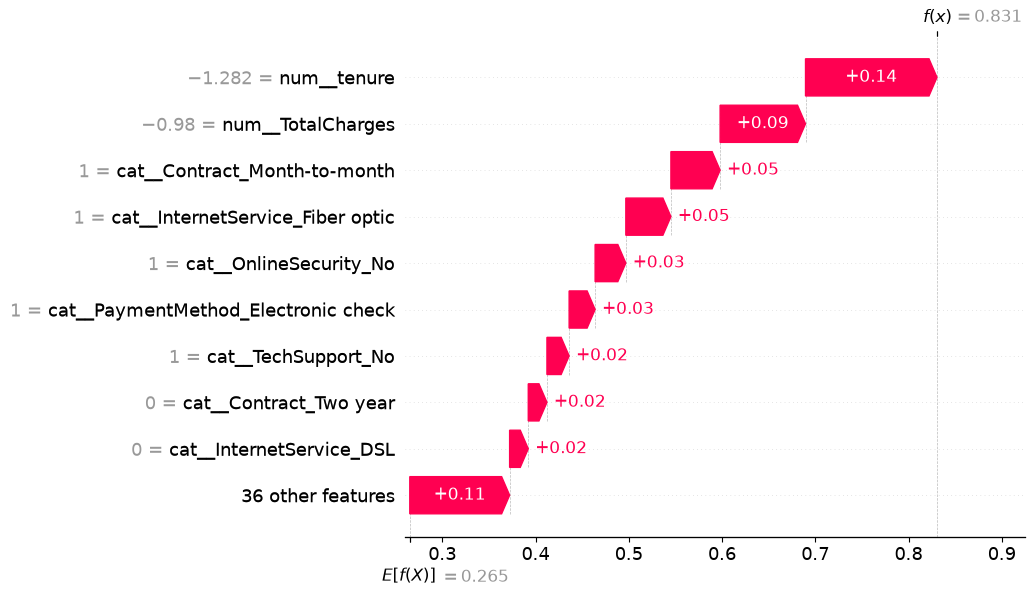

In [81]:
# Find correctly predicted churn customers (True Positives)
tp_positions = np.where(
    (np.array(y_val) == 1) & (final_predictions == 1)
)[0]

# Select the first customer
tp_position = tp_positions[0]

print("Customer index:", X_val.index[tp_position])
print("Actual:", y_val.iloc[tp_position])
print("Predicted:", final_predictions[tp_position])

# Explain the prediction using SHAP
shap.plots.waterfall(shap_values[tp_position, :, 1])

Actual: 1
Predicted: 1
Churn probability: 0.8305350372087161


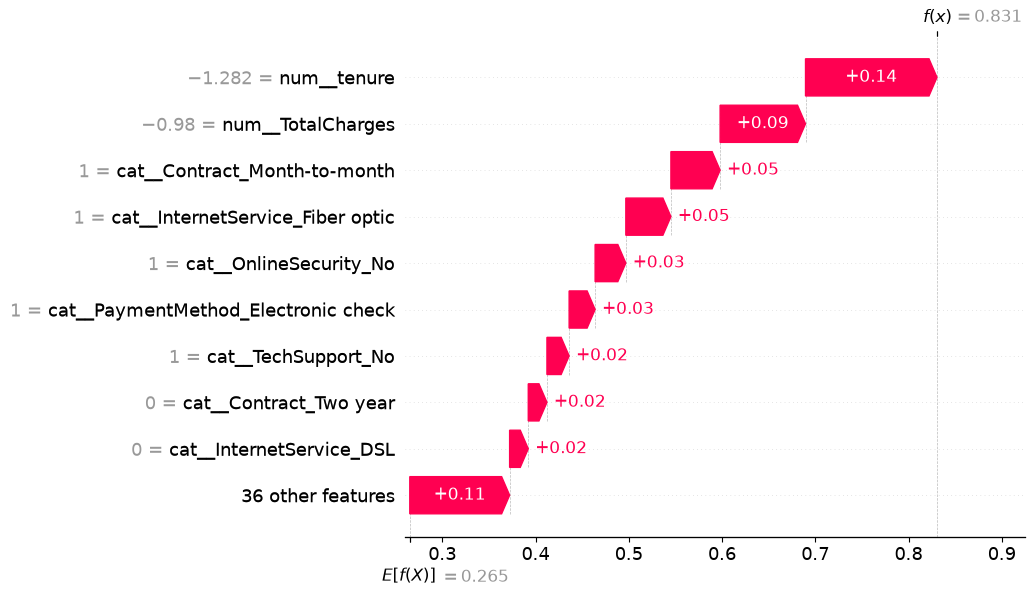

In [82]:
# Find a True Positive: actual churn and predicted churn
tp_positions = np.where(
    (np.array(y_val) == 1) & (final_predictions == 1)
)[0]

tp_position = tp_positions[0]

print("Actual:", y_val.iloc[tp_position])
print("Predicted:", final_predictions[tp_position])
print("Churn probability:",
      final_model.predict_proba(X_val.iloc[[tp_position]])[0][1])

shap.plots.waterfall(shap_values[tp_position, :, 1])

Actual: 0
Predicted: 1
Churn probability: 0.5349286530329047


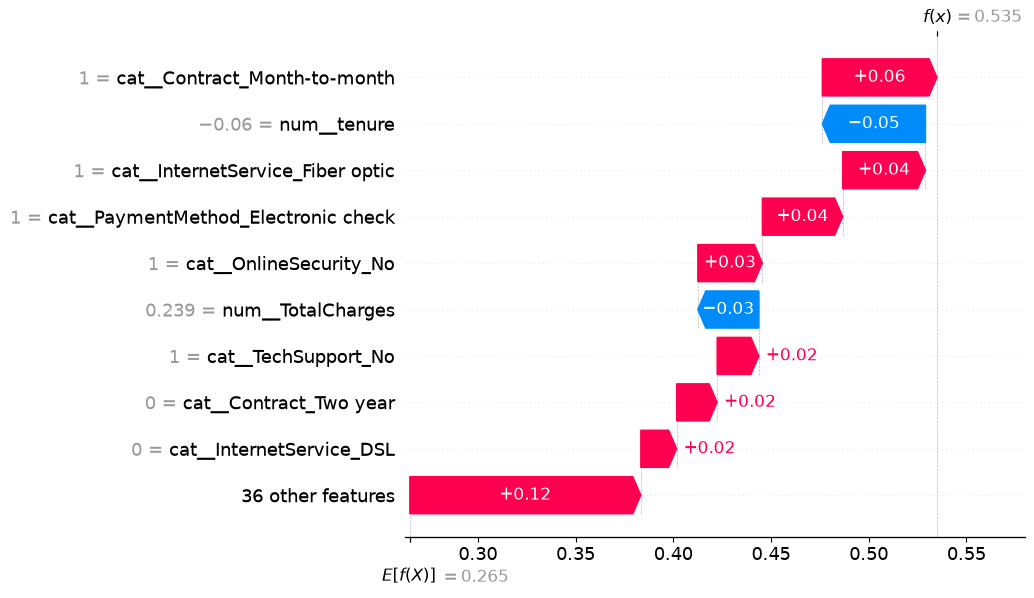

In [83]:
# Find a False Positive
fp_positions = np.where(
    (np.array(y_val) == 0) & (final_predictions == 1)
)[0]

fp_position = fp_positions[0]

print("Actual:", y_val.iloc[fp_position])
print("Predicted:", final_predictions[fp_position])
print("Churn probability:",
      final_model.predict_proba(X_val.iloc[[fp_position]])[0][1])

shap.plots.waterfall(shap_values[fp_position, :, 1])

### SHAP Explainability – Conclusion

SHAP (SHapley Additive exPlanations) was used to understand how individual features influence the Random Forest model's predictions.

The summary plot showed that the most influential features were Contract (Month-to-month), Tenure, Internet Service (Fiber optic), Online Security, Total Charges, and Tech Support.

The results indicated that customers with month-to-month contracts, shorter tenure, fiber optic internet, and no online security or technical support generally received higher churn predictions.

Individual SHAP explanations were also used to investigate different prediction types:

1. **False Negative:** The customer actually churned, but the model predicted No Churn. The predicted churn probability was 34.82%. Some features increased the churn prediction, while tenure and total charges decreased it.
2. **True Positive:** A customer who actually churned and was correctly predicted as a churner.
3. **False Positive:** A customer who did not churn but was incorrectly predicted as a churner.

SHAP helped explain both correct and incorrect predictions by showing how individual features contributed to the model's output.

**Overall conclusion:** SHAP improved the interpretability of the Random Forest model and helped us understand why it made particular predictions.

## 12. Final evaluation on the test set



In [84]:
comparison_df = pd.DataFrame({
    "Model": ["Baseline Random Forest", "Tuned Random Forest"],
    "Mean CV F1": [0.6020, 0.5832],
    "Std CV F1": [0.0238, 0.0185]
})

comparison_df

,Model,Mean CV F1,Std CV F1
0,Baseline Random Forest,0.6020,0.0238
1,Tuned Random Forest,0.5832,0.0185


### Model Comparison and Final Decision

The baseline Random Forest and tuned Random Forest were compared using cross-validation.

The baseline model achieved a higher mean F1 score of 0.6020 compared with 0.5832 for the tuned model. This indicates that the baseline model had better average predictive performance.

However, the tuned model had a lower standard deviation (0.0185 compared with 0.0238), indicating slightly more consistent results across folds.

The tuned model also showed a gap between training F1 (0.7396) and validation F1 (0.5832), suggesting some overfitting.

**Final Decision:**

Based on the available cross-validation results, the baseline Random Forest achieved better predictive performance, while the tuned Random Forest was slightly more consistent.

Hyperparameter tuning did not improve the F1 score in this experiment. Therefore, tuning should not automatically be considered an improvement simply because the model has optimized parameters.

The final model choice should also consider error analysis, execution time, model complexity, and explainability.

In [85]:
from sklearn.metrics import classification_report, confusion_matrix

final_predictions = final_model.predict(X_val)

print("Final Model Confusion Matrix:")
print(confusion_matrix(y_val, final_predictions))

print("\nFinal Model Classification Report:")
print(classification_report(y_val, final_predictions))

Final Model Confusion Matrix:
[[783  45]
 [100 199]]

Final Model Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92       828
           1       0.82      0.67      0.73       299

    accuracy                           0.87      1127
   macro avg       0.85      0.81      0.82      1127
weighted avg       0.87      0.87      0.87      1127



### Final Model Evaluation

The tuned Random Forest model was evaluated on the validation dataset containing 1,127 customers.

The model achieved:
- Accuracy: 87%
- Churn Precision: 81%
- Churn Recall: 65%
- Churn F1-score: 0.72

The confusion matrix showed 781 True Negatives, 195 True Positives, 47 False Positives, and 104 False Negatives.

Compared with the earlier permutation model, the tuned model achieved better validation performance and reduced the number of False Negatives from 150 to 104.

However, the cross-validation results showed that the baseline model had a higher mean F1-score (0.6020) than the tuned model (0.5832). This demonstrates why both cross-validation and separate validation performance should be considered when comparing models.

Overall, the tuned Random Forest showed promising performance on the validation split, especially in identifying customers likely to churn. Further evaluation on the untouched test set is needed before making a final generalization claim.

In [86]:

from sklearn.metrics import classification_report, confusion_matrix

test_predictions = final_model.predict(X_test)

print("Test Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nTest Classification Report:")
print(classification_report(y_test, test_predictions))

Test Confusion Matrix:
[[933 102]
 [180 194]]

Test Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



### Final Test Evaluation

The tuned Random Forest model was evaluated on the untouched test dataset containing 1,409 customers.

The model achieved:
- Accuracy: 80%
- Churn Precision: 67%
- Churn Recall: 52%
- Churn F1-score: 0.58

The confusion matrix showed:
- 938 True Negatives
- 193 True Positives
- 97 False Positives
- 181 False Negatives

The model correctly identified many customers who would stay, but it missed 181 customers who actually churned.

Compared with the validation results, the model's performance decreased on the test set. This indicates that its performance on validation data was more optimistic than its performance on unseen data.

The test F1-score of approximately 0.58 was close to the cross-validation F1-score of 0.5832, suggesting that cross-validation provided a useful estimate of generalization performance.

**Final conclusion:** The tuned Random Forest achieved reasonable predictive performance, but its churn recall needs improvement. Further work could investigate class weights, decision threshold adjustment, and other models to reduce missed churn customers.